In [1]:
import sympy as sp
import numpy as np
import pandas as pd
import scipy
from sympy.physics.mechanics import dynamicsymbols, ReferenceFrame
from sympy import  symbols, sin , cos, lambdify, atan, acos, nsolve
from scipy.optimize import fsolve, least_squares, differential_evolution
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# Taller 2
Laura Perilla - 202216526

In [2]:
file_path = 'splines.csv'
data = pd.read_csv(file_path, delimiter=',') 
data = data.drop(['CODIGO'], axis = 1)
num = 100 #Numero de puntos tanto para el spline como para la trayectoria (cinematica)

for i in data:
    data[i] = data[i].multiply(1/1000)

data.head()

,X1,Y1,X2,Y2,X3,Y3,X4,Y4
0,0.3,0.20000,0.34459,0.19626,0.29793,0.22130,0.25897,0.20000
1,0.3,0.18660,0.33710,0.22790,0.29793,0.22130,0.25897,0.20000
2,0.3,0.16944,0.35140,0.21909,0.31767,0.20663,0.26194,0.18528
3,0.3,0.18983,0.35380,0.21210,0.30000,0.20295,0.26194,0.18528
4,0.3,0.21998,0.35448,0.20094,0.29910,0.23578,0.27954,0.21652


In [3]:
def plotSpline(n):
    p_list = np.array([[data['X1'][n], data['Y1'][n]], [data['X2'][n], data['Y2'][n]], [data['X3'][n], data['Y3'][n]],\
                       [data['X4'][n], data['Y4'][n]], [data['X1'][n], data['Y1'][n]]]) 
    x_l = p_list[:, 0] #los 4 puntos que determinan el spline
    y_l = p_list[:, 1]

    spline_x = CubicSpline(range(len(x_l)), x_l, bc_type='periodic')
    spline_y = CubicSpline(range(len(y_l)), y_l, bc_type='periodic')

    t_l = np.linspace(0, len(x_l) - 1, num)
    x_p = spline_x(t_l) #Lista de puntos de los splines
    y_p = spline_y(t_l)

    spl_l = [[x_p, y_p], [x_l, y_l]]
    
    return np.column_stack((spl_l[0][0], spl_l[0][1]))

In [4]:
theta1, theta2, theta3, theta4 = dynamicsymbols('theta1, theta2, theta3, theta4')
t = symbols('t')
l_OA, l_AB, l_BC, l_CD, l_AS, l_AD = symbols('OA, AB, BC, CD, AS, AD')

N = ReferenceFrame('N')
A = N.orientnew('A', 'Axis', (N.z, theta1))
B = A.orientnew('B', 'Axis', (N.z, -theta2))
C = B.orientnew('C', 'Axis', (N.z, -theta3))
D = N.orientnew('D', 'Axis', (N.z, -theta4))

thetadot1 = 1 #Relación de engranajes 1:1
thetadot2 = 1

t_ = np.linspace(0, 2*np.pi, num)
theta_1 = list(np.deg2rad(90) + thetadot1*t_)
theta_4 = list(np.deg2rad(90) - thetadot2*t_)

posicion = l_OA*A.x + l_AB*B.x + l_BC*C.x + l_CD*D.x - l_AD*N.x
posicion_fun = lambdify([l_OA, l_AB, l_BC, l_CD, l_AD, theta1, theta2, theta3, theta4], [posicion.dot(N.x), posicion.dot(N.y)])

eq2 = l_OA*A.x + l_AS*B.x
pos2 = lambdify([l_OA, l_AS, theta1, theta2], [eq2.dot(N.x), eq2.dot(N.y)])

def trayectoria(OA, AB, BC, CD, AS, AD): 
    z0 = [np.deg2rad(50), np.deg2rad(90)] 
    theta_2, theta_3 = [], []

    for i in range(len(t_)):
        fsolve_fun = lambda z: posicion_fun(OA, AB, BC, CD, AD, theta_1[i], z[0], z[1], theta_4[i])
        out = least_squares(fsolve_fun, z0)
        sln = [theta_1[i], out.x[0], out.x[1], theta_4[i]]
        z0 = [sln[1], sln[2]]
        theta_2.append(sln[1]); theta_3.append(sln[2])
        
        if out.cost > 1*10**(-6):
            return np.array([[None, None], [None, None]]).T

    x_pos, y_pos = [], []
    for i in range(len(t_)):
        x, y = pos2(OA, AS, theta_1[i], theta_2[i])
        x_pos.append(x); y_pos.append(y)
    
    return [[x_pos, y_pos], [OA, AB, BC, CD, AS, AD], (theta_1, theta_2, theta_3, theta_4)] 

In [5]:
def centroid(x, y):
    x_c, y_c = np.average(x), np.average(y)
    return [x_c, y_c]

def CurveLength(spline):  
    xx, yy = spline[:, 0], spline[:, 1]
    return np.sum(np.sqrt(np.diff(xx)**2+np.diff(yy)**2))

def er_fun(spline, spl_star):
    tree = scipy.spatial.KDTree(spl_star) #Halla los puntos mas cercanos 
    dists, indices = tree.query(spline)

    l = CurveLength(spline)
    l_star = CurveLength(spl_star)

    return sum(dists)/(len(spl_star)) + 0.05*np.abs(l-l_star) 

In [6]:
def CompararSpls(spl_star, x):
    x_c, y_c = centroid(spl_star[:, 0], spl_star[:, 1])
    trazo = np.array(trayectoria(x[0], x[1], x[2], x[3], x[4], x[5])[0]).T

    if None in trazo: #Penalizar si hay un spline que no cierra
        return 10000
    
    x_c1, y_c1 = centroid(trazo[:,0], trazo[:,1])
    trasl = np.array([x_c - x_c1, y_c - y_c1]) #Curva trasladada al centroide del spline asignado
    spl_guess = np.array((trazo[:,0] + trasl[0],  trazo[:,1] + trasl[1])).T
    
    er = er_fun(spl_guess, spl_star)
    return er

In [7]:
def opt_fun(x, spl_star):
    cebolla = x[0], x[1], x[2], x[3], x[4], x[5]
    return CompararSpls(spl_star, cebolla)

# out = differential_evolution(opt_fun, bounds=[(0.006, 0.009),(0.02, 0.04),(0.03, 0.06),(0.01, 0.03),(0.09, 0.15),(0.05, 0.07)],
#                              args=(spl_19,), popsize=2, x0 = [0.007, 0.03, 0.05, 0.02, 0.12, 0.06])

opt_params = [0.00601663, 0.03222794, 0.0313002, 0.01801227, 0.13830748, 0.05027739]

In [8]:
#Traslado el spline asignado al centroide del spline que obtuve 
spl_guess = np.array(trayectoria(*opt_params)[0]).T
x_c1, y_c1 = centroid(spl_guess[:,0], spl_guess[:,1])

spl_19 = plotSpline(19) #Selecciono el spline que me tocó :)
x_c, y_c = centroid(spl_19[:, 0], spl_19[:, 1]) 

trasl = np.array([x_c1 - x_c, y_c1 - y_c])
spl_19 = np.array((spl_19[:,0] + trasl[0],  spl_19[:,1] + trasl[1])).T

In [9]:
import matplotlib.animation as animation
from IPython.display import HTML

OA_val, AB_val, BC_val, CD_val, AS_val, AD_val = opt_params

angles = trayectoria(OA_val, AB_val, BC_val, CD_val, AS_val, AD_val)[2]

fig, ax = plt.subplots(figsize=(9, 5))
path_S_x, path_S_y = [], []

def update(frame, spl_star):
    ax.cla()
    ax.set_xlim(-0.05, 0.2)
    ax.set_ylim(-0.05, 0.15)
    ax.set_xlabel("Posición en X (m)")
    ax.set_ylabel("Posición en Y (m)")
    ax.set_title("Mecanismo animado")
    ax.grid(True)
    ax.set_aspect('equal', adjustable='box')
    
    th1 = angles[0][frame]
    th2 = angles[1][frame]
    th3 = angles[2][frame]
    th4 = angles[3][frame]

    O = np.array([0, 0])
    A_pos = np.array([OA_val * np.cos(th1), OA_val * np.sin(th1)])
    B_pos = A_pos + np.array([AB_val * np.cos(th1 - th2), AB_val * np.sin(th1 - th2)])
    C_pos = B_pos + np.array([BC_val * np.cos(th1 - th2 - th3), BC_val * np.sin(th1 - th2 - th3)])
    D_pos = np.array([AD_val, 0])
    
    S_pos = A_pos + np.array([AS_val*np.cos(th1 - th2), AS_val*np.sin(th1 - th2)])
    path_S_x.append(S_pos[0])
    path_S_y.append(S_pos[1])
    
    ax.plot([O[0], A_pos[0]], [O[1], A_pos[1]])
    ax.plot([A_pos[0], B_pos[0]], [A_pos[1], B_pos[1]])
    ax.plot([B_pos[0], C_pos[0]], [B_pos[1], C_pos[1]])
    ax.plot([C_pos[0], D_pos[0]], [C_pos[1], D_pos[1]])
    ax.plot([A_pos[0], S_pos[0]], [A_pos[1], S_pos[1]])
    ax.plot(path_S_x, path_S_y, 'k--', label = 'Aproximación')
    ax.plot(spl_star[:,0], spl_star[:,1], label = 'Spline Asignado', color = 'orange')

    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    
ani = animation.FuncAnimation(fig, update, frames=len(t_), interval=50, fargs=(spl_19,))
plt.close(fig)
HTML(ani.to_jshtml())

### Punto 2

In [10]:
#Parametros optimizados 
OA_v, AB_v, BC_v, CD_v, AS_v, AD_v = opt_params

den = 2.81*(1/1000)*100**3 #[kg/m^3]
va, vb, vc, vd = (np.pi*OA_v**2)*0.005, AS_v*0.005**2, BC_v*0.005**2, CD_v*0.005**2
ma, mb, mc, md = va*den, vb*den, vc*den, vd*den

In [11]:
pos = OA_v*A.x + AB_v*B.x + BC_v*C.x + CD_v*D.x - AD_v*N.x
vel = pos.diff(t, N).simplify()
ace = vel.diff(t, N).simplify()

theta_2, theta_3 = [], []
pos_fun = lambdify([theta1, theta2, theta3, theta4], [pos.dot(N.x), pos.dot(N.y)])

theta_1 = list(np.deg2rad(90) + thetadot1*t_)
theta_4 = list(np.deg2rad(90) - thetadot2*t_)

z0 = [np.deg2rad(50), np.deg2rad(90)] 

def posicion(i, z0 = None):
    fsolve_fun = lambda z: pos_fun(theta_1[i], z[0], z[1], theta_4[i])
    out = least_squares(fsolve_fun, z0)    
    return [theta_1[i], out.x[0], out.x[1], theta_4[i]]

for i in range(len(t_)):
    sln = posicion(i, z0)
    z0 = [sln[1], sln[2]]
    theta_2.append(sln[1])
    theta_3.append(sln[2])

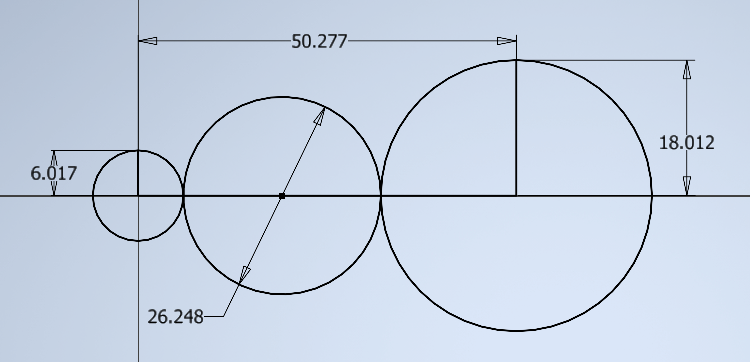

- Usé inventor para hallar las dimensiones del idler y así poder plantear la relación entre los 'engranajes' y el momento de entrada

$$M_{eng} = M_{in} \cdot \frac{d_{eng}}{d_{idler}}

In [12]:
Ia, Ib, Ic, Id = (1/2)*ma*OA_v**2, (1/12)*mb*AS_v**2, (1/12)*mc*BC_v**2, (1/2)*md*CD_v**2
foax, foay, fabx, faby, fbcx, fbcy, fcdx, fcdy, fodx, fody, Min, Min2 = dynamicsymbols('foax, foay, fabx, faby, fbcx, fbcy, fcdx, fcdy, fodx, fody, Min, Min2')

foa = foax*N.x + foay*N.y
fab = fabx*N.x + faby*N.y
fbc = fbcx*N.x + fbcy*N.y
fcd = fcdx*N.x + fcdy*N.y
fod = fodx*N.x + fody*N.y

a_cm = 0*N.x + 0*N.y
b_cm = OA_v*A.x + (AS_v/2)*B.x
c_cm = OA_v*A.x + AS_v*B.x + (BC_v/2)*C.x
d_cm = OA_v*A.x + AS_v*B.x + BC_v*C.x + CD_v*D.x

Foa = foa - fab - ma*9.81*N.y - ma*a_cm.diff(t,N).diff(t,N)
Fab = fab - fbc - mb*9.81*N.y - mb*b_cm.diff(t,N).diff(t,N)
Fbc = fbc - fcd - mc*9.81*N.y - mc*c_cm.diff(t,N).diff(t,N)
Fcd = fcd + fod - md*9.81*N.y - md*d_cm.diff(t,N).diff(t,N)

M1 = - 0.02*theta1.diff(t)*N.z
M2 = 0.02*theta2.diff(t)*N.z
M3 = 0.02*theta3.diff(t)*N.z
M4 = - 0.02*(theta1-theta2-theta3).diff(t)*N.z
M5 = 0.02*theta4.diff(t)*N.z

Moa = M1 - M2 + Min*(0.46)*N.z + OA_v*A.x.cross(-fab)  - Ia*theta1.diff(t,t)*N.z
Mab = M2 - M3 - (AS_v/2)*B.x.cross(fab) + (AB_v-(AS_v/2))*B.x.cross(-fbc) - Ib*(theta1-theta2).diff(t,t)*N.z
Mbc = M3 - M4 - (BC_v/2)*C.x.cross(fbc) + (BC_v/2)*C.x.cross(-fcd) - Ic*(theta1-theta2-theta3).diff(t,t)*N.z
Mcd = M4 + M5 + Min*(1.37)*N.z + CD_v*D.x.cross(fcd) + Id*theta4.diff(t,t)*N.z

eqList = []
for eq in [Foa, Fab, Fbc, Fcd]:
    eqList.append(eq.simplify().dot(N.x))
    eqList.append(eq.simplify().dot(N.y))

for eq in [Moa, Mab, Mbc, Mcd]:
    eqList.append(eq.simplify().dot(N.z))

pos_var = [theta1, theta2, theta3, theta4]
vel_var = [theta1.diff(t), theta2.diff(t), theta3.diff(t), theta4.diff(t)]
ace_var = [theta1.diff(t,t), theta2.diff(t,t), theta3.diff(t,t), theta4.diff(t,t)]

pos_fun = lambdify([theta1, theta2, theta3, theta4], [pos.dot(N.x), pos.dot(N.y)])

[AV, bV] = sp.linear_eq_to_matrix([vel.dot(N.x), vel.dot(N.y)], [theta2.diff(t), theta3.diff(t)])
AV_fun = sp.lambdify(pos_var + vel_var, AV)
bV_fun = sp.lambdify(pos_var + vel_var, bV)

[AA, bA] = sp.linear_eq_to_matrix([ace.dot(N.x), ace.dot(N.y)], [theta2.diff(t,t), theta3.diff(t,t)])
AA_fun = sp.lambdify(pos_var + vel_var + ace_var, AA)
bA_fun = sp.lambdify(pos_var + vel_var + ace_var, bA)

cinemat = [foax, foay, fabx, faby, fbcx, fbcy, fcdx, fcdy, fodx, fody, Min]

[RR, b] = sp.linear_eq_to_matrix(eqList, cinemat)
R_fun = sp.lambdify(pos_var + vel_var + ace_var, RR)
b_fun = sp.lambdify(pos_var + vel_var + ace_var, b)

In [13]:
q0 = [np.deg2rad(50), np.deg2rad(90)] 

def cinematica(i, theta1dot, theta1ddot, theta4dot, theta4ddot, q0):
    p = posicion(i, q0)
    args = [*p, theta1dot, None, None, theta4dot]
    pdot = np.concatenate([[theta1dot], np.matmul(np.linalg.pinv(AV_fun(*args)), bV_fun(*args)).flatten(), [theta4dot]])
    args2 = [*p, *pdot, theta1ddot, None, None, theta4ddot]
    pddot = np.concatenate([[theta1ddot], np.matmul(np.linalg.pinv(AA_fun(*args2)), bA_fun(*args2)).flatten(), [theta4ddot]])
    return [p[0], p[1], p[2], p[3], *pdot, *pddot]

def inv_dinam(index, theta1dot, theta1ddot, theta4dot, theta4ddot, q0):
    args = cinematica(index, theta1dot, theta1ddot, theta4dot, theta4ddot, q0)
    outF = np.matmul(np.linalg.pinv(R_fun(*args)), b_fun(*args)).flatten()
    return outF

M_list = [] 

for i in range(len(t_)):
    sln = cinematica(i, thetadot1, 0, -thetadot2, 0, q0)
    out = inv_dinam(i, thetadot1, 0, -thetadot2, 0, q0)
    q0 = [sln[1], sln[2]]
    M_list.append(out[10])

Mavg = np.array([np.average(M_list)]*len(t_))

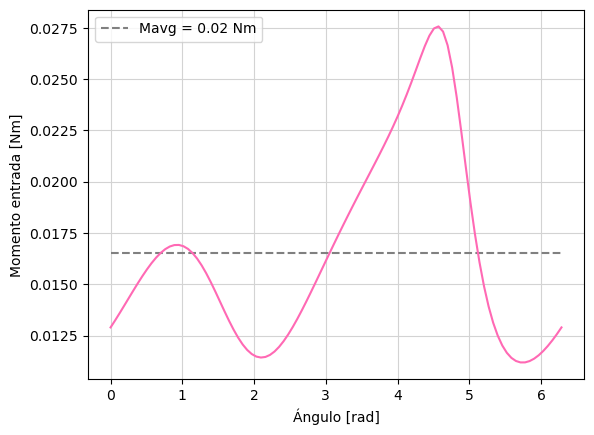

In [14]:
ang = np.linspace(0, 2*np.pi, num)

plt.plot(ang, Mavg, color = 'gray', linestyle='dashed', label = 'Mavg = ' + str(round(np.average(M_list), 2)) + ' Nm')
plt.plot(ang, M_list, color='hotpink')
plt.ylabel('Momento entrada [Nm]'); plt.xlabel('Ángulo [rad]')
plt.legend(); plt.grid(True, color = 'lightgrey')

In [15]:
omega_max = 100*(2*np.pi/60)
omega_min = 80*(2*np.pi/60)
omega_avg = np.average([omega_max, omega_min])
k = (omega_max - omega_min) / omega_avg #Coeficiente de fluctuación

C:\Users\laura\AppData\Local\Temp\ipykernel_10784\3489664840.py:1: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area_pos = np.trapz((M_list - Mavg)[M_list > Mavg], x=ang[M_list > Mavg])
C:\Users\laura\AppData\Local\Temp\ipykernel_10784\3489664840.py:2: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area_neg = abs(np.trapz((M_list - Mavg)[M_list < Mavg], x=ang[M_list < Mavg]))


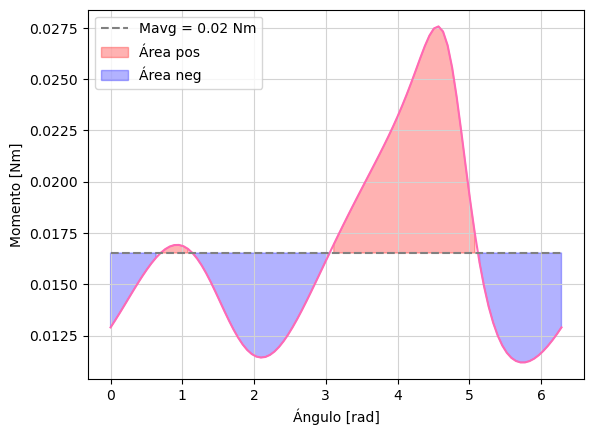

In [16]:
area_pos = np.trapz((M_list - Mavg)[M_list > Mavg], x=ang[M_list > Mavg])
area_neg = abs(np.trapz((M_list - Mavg)[M_list < Mavg], x=ang[M_list < Mavg]))

plt.plot(ang, M_list, color='hotpink')
plt.plot(ang, Mavg, color = 'gray', linestyle='dashed', label = 'Mavg = ' + str(round(np.average(M_list), 2)) + ' Nm')

plt.fill_between(ang, M_list, Mavg, where=M_list > Mavg, color='red', alpha=0.3, label='Área pos')
plt.fill_between(ang, M_list, Mavg, where=M_list < Mavg, color='blue', alpha=0.3, label='Área neg')

plt.legend(); plt.xlabel('Ángulo [rad]'); plt.ylabel('Momento [Nm]'); plt.grid(True, color = 'lightgrey'); plt.show()

In [17]:
E = max(area_pos, area_neg)
Is = E/(k*omega_avg**2)

m_i = Is/(0.03**2)
print('El volante de inercia necesario es de: 3 cm de diametro y con una masa de: ' + str(round(m_i, 4)) + ' kg')

El volante de inercia necesario es de: 3 cm de diametro y con una masa de: 0.7102 kg


BONO :)

In [18]:
length = np.linspace(0.002, 0.1, 4)
params = np.meshgrid(length, length, length, length, length, length)
params = np.array([p.flatten() for p in params]).T
trays = []

for i in range(len(params)):
    trays.append(trayectoria(*params[i])) 

# with Pool(processes = 16) as pool: 
#     resultados = pool.map(trayectoria, params)

In [19]:
def Normalize(spl):
    centro = spl.mean(axis=0)
    spl = spl - centro
    svd = np.linalg.svd(spl)
    if np.linalg.det(svd.Vh) < 0: #Verificar si está haciendo espejo
        svd.Vh[-1, :] *= -1 
    spl = np.matmul(svd.Vh, spl.T).T / np.max(svd.S)
    return spl, [centro, svd.Vh, np.max(svd.S)]

#Creo una lista con las trayectorias que me sirven
clean_trays = []
dimensiones = []
for i in range(len(trays)):
    coords = np.array(trays[i][0]).T
    if None not in coords:
        if sum([abs(coords[:1][:,0][0]-coords[-1:][:,0][0]), abs(coords[:1][:,1][0]-coords[-1:][:,1][0])]) < 1*10**(-4):
            clean_trays.append(Normalize(coords))
            dimensiones.append(trays[i][1])

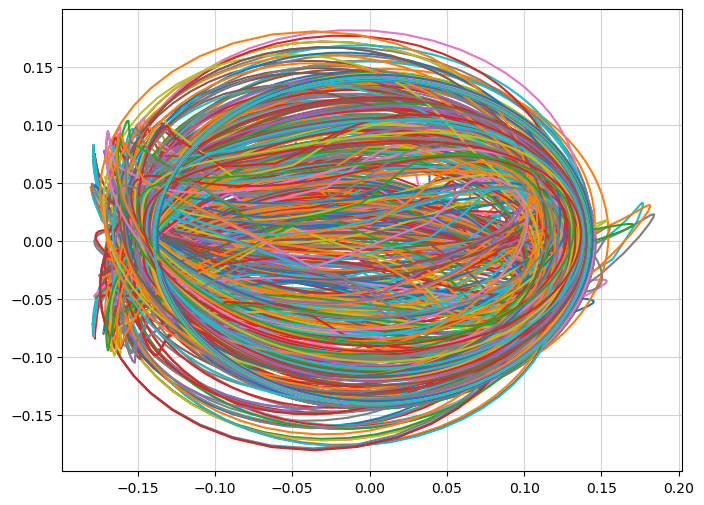

In [20]:
plt.figure(figsize=(8, 6))
for idx, (coords, _) in enumerate(clean_trays):
    x, y = coords[:, 0], coords[:, 1]
    plt.plot(x, y)
    plt.grid(True, color = 'lightgrey')

In [21]:
def elipticidad(spline):
    points = np.array(spline)
    cov = np.cov(points.T)
    eigvals = np.linalg.eigvalsh(cov)
    major = np.max(eigvals)
    minor = np.min(eigvals)
    return 1 - minor / major

def ellip_er(spline, spl_star):
    return abs(elipticidad(spline) - elipticidad(spl_star))

def total_er(spline, spl_star):
    return (abs(0.8*er_fun(spline, spl_star)) + 0.2*ellip_er(spline, spl_star))

In [22]:
def opt_fun2(x, spl_star):
    cebolla = x[0], x[1], x[2], x[3], x[4], x[5]
    spl = np.array(trayectoria(*cebolla)[0]).T
    if None in spl:
        return 1000 #Vuelvo a verificar si hay trayectorias que no cierran 
    return total_er(spl, spl_star)

las dimensiones del mecanismo son: [np.float64(0.002), np.float64(0.1), np.float64(0.1), np.float64(0.03466666666666667), np.float64(0.1), np.float64(0.1)]


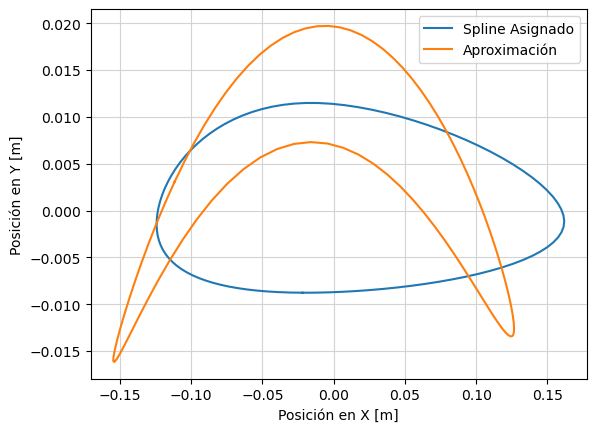

In [23]:
spl_star_s, norm = Normalize(plotSpline(24)) 
  
min_er = 1
spl = None
for idx, (guess, _) in enumerate(clean_trays):
    er = total_er(spl_star_s, guess)
    if er < min_er:
        min_er, spl, index = er, guess, idx

# out = least_squares(opt_fun2, params_0, args=(spl_star_s,))
# out = differential_evolution(opt_fun2, bounds=[(0.002, 0.1),(0.002, 0.1),(0.002, 0.1),(0.002, 0.1),(0.002, 0.1),(0.002, 0.1)],
#                              args=(spl_star_s,), popsize=2, x0 = params_0)

print('las dimensiones del mecanismo son: ' + str(dimensiones[index]))

plt.plot(spl_star_s[:,0],spl_star_s[:,1])
plt.plot(spl[:,0], spl[:,1])
plt.legend(['Spline Asignado', 'Aproximación'], loc = 'upper right')
plt.grid(True, color = 'lightgrey')
plt.xlabel('Posición en X [m]')
plt.ylabel('Posición en Y [m]')
plt.show()

- El código funciona para la mitad de los splines, la vdd nose porque con los que tienen forma redonda se putea :(

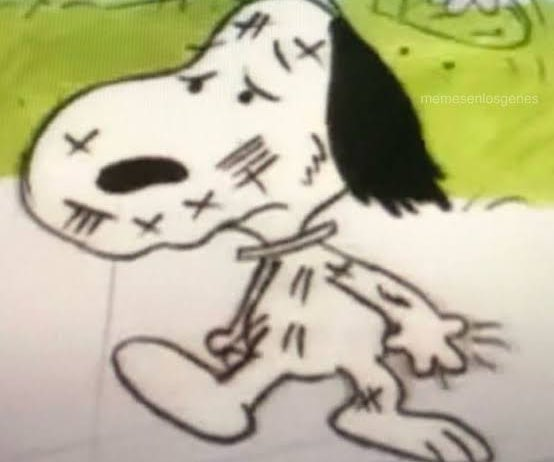

In [24]:
def Denormalize(X, norm):
    spl_desn = np.matmul((X*norm[2]), np.linalg.inv(norm[1])) + norm[0] 
    return spl_desn

spl_star_d = Denormalize(spl_star_s, norm)

OA_val, AB_val, BC_val, CD_val, AS_val, AD_val = dimensiones[index]
angles = trayectoria(OA_val, AB_val, BC_val, CD_val, AS_val, AD_val)[2]

fig, ax = plt.subplots(figsize=(9, 5))
path_S_x, path_S_y = [], []

def update(frame):
    ax.cla()
    ax.set_xlim(0.2, 0.4)
    ax.set_ylim(0.15, 0.3)
    ax.set_xlabel("Posición en X (m)")
    ax.set_ylabel("Posición en Y (m)")
    ax.set_title("Mecanismo animado")
    ax.grid(True)
    ax.set_aspect('equal', adjustable='box')
    
    th1 = angles[0][frame]
    th2 = angles[1][frame]
    th3 = angles[2][frame]
    th4 = angles[3][frame]
    
    O = np.array([0, 0])
    A = np.array([OA_val * np.cos(th1), OA_val * np.sin(th1)])
    B = A + np.array([AB_val * np.cos(th1 - th2), AB_val * np.sin(th1 - th2)])
    C = B + np.array([BC_val * np.cos(th1 - th2 - th3), BC_val * np.sin(th1 - th2 - th3)])
    D = np.array([AD_val, 0]) 
    S = A + np.array([AS_val * np.cos(th1 - th2), AS_val * np.sin(th1 - th2)])
    
    O_d = Denormalize(O, norm); A_d = Denormalize(A, norm); B_d = Denormalize(B, norm); C_d = Denormalize(C, norm)
    D_d = Denormalize(D, norm); S_d = Denormalize(S, norm)
    
    path_S_x.append(S_d[0])
    path_S_y.append(S_d[1])

    ax.plot([O_d[0], A_d[0]], [O_d[1], A_d[1]])
    ax.plot([A_d[0], B_d[0]], [A_d[1], B_d[1]])
    ax.plot([B_d[0], C_d[0]], [B_d[1], C_d[1]])
    ax.plot([C_d[0], D_d[0]], [C_d[1], D_d[1]])
    ax.plot([A_d[0], S_d[0]], [A_d[1], S_d[1]])
    
    # ax.plot(spl_star_d[:,0], spl_star_d[:,1], label = 'Spline Asignado', color = 'orange')
    ax.plot(path_S_x, path_S_y, 'k--', label='Trayectoria S')
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

ani = animation.FuncAnimation(fig, update, frames=len(t_), interval=50)
plt.close(fig)
HTML(ani.to_jshtml())

KeyboardInterrupt: 